# ZeroWaste — Train on real kitchen records in Jupyter

Is notebook mein tum khud cells run karke models train karogi. Training ka actual
`.fit()` call Step 5 mein hai. Notebook open karne se training automatically nahi hoti.

**Data:** [URBAN-WASTE Food Tracking Device](https://zenodo.org/records/3355300),
Mattias Eriksson and Samuel Lindgren (2019), recorded at pilot hotels/restaurants.
**Task:** known kitchen ka next-day waste, uski measured past history se predict karna.

CSV ki exact weight unit explicitly documented nahi hai. Outputs ko **source weight units**
kehna; abhi kg, rupees ya preparation recommendation claim mat karna.

**Setup:** project terminal mein `.venv/bin/python -m pip install -r requirements-notebook.txt`.
VS Code mein notebook kholo → **Select Kernel → Python Environments → .venv**.
Cells top-to-bottom run karo (`Shift+Enter`). Kernel ka Python path first cell mein verify karo.
Standalone Jupyter users: install `jupyterlab` in this environment and run `python -m jupyter lab`.

## 1. Imports and project location
Notebook shared cleaning/feature functions use karti hai, taaki CLI aur notebook ka logic same rahe.
Project root aur `notebooks/` dono working directories supported hain.

In [1]:
from pathlib import Path
import sys
import json
import pickle
import platform
import hashlib

search_paths = [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in search_paths if (p / 'real_data.py').exists()), None)
if ROOT is None:
    raise RuntimeError('Open this notebook inside the ZeroWaste project folder.')
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display
from sklearn.base import clone
from real_data import (
    RAW_PATH, CLEAN_PATH, TARGET, UNIT, FEATURES,
    load_clean_data, build_forecast_rows, chronological_split,
)
from train_real_model import candidates, scores, BASELINES, predict_selected
from predict_real_waste import forecast

print('Kernel Python:', sys.executable)
print('Project:', ROOT)
print('Target unit:', UNIT)

Kernel Python: /Users/namitachhabra/Documents/zerowaste/.venv/bin/python
Project: /Users/namitachhabra/Documents/zerowaste
Target unit: source weight units (exact CSV unit unconfirmed)


## 2. Load and clean real observations
Source file semicolon-separated hai, decimal commas aur Western European text use karti hai.
Cleaning dates/weights parse karti hai aur duplicate kitchen/date reject karti hai.
**Missing waste ko zero nahi banayenge.** Zero actual measured value bhi ho sakta hai.
Same-day portions/served counts ko pre-service inputs nahi banayenge.

In [2]:
raw = pd.read_csv(RAW_PATH, sep=';', encoding='cp1252', dtype=str)
clean = load_clean_data()
print('Raw shape:', raw.shape)
print('Kitchen count:', clean.kitchen.nunique())
print('Dates:', clean.date.min().date(), 'to', clean.date.max().date())
print('Measured targets:', clean[TARGET].notna().sum())
print('Missing targets:', clean[TARGET].isna().sum())
display(clean.head(10))
display(raw.isna().sum().to_frame('missing_rows'))
CLEAN_PATH.parent.mkdir(parents=True, exist_ok=True)
clean.to_csv(CLEAN_PATH, index=False, date_format='%Y-%m-%d')

Raw shape: (3321, 13)
Kitchen count: 34
Dates: 2018-03-02 to 2018-11-21
Measured targets: 3160
Missing targets: 161


,kitchen,date,waste_weight
0,Copenhagen / 66,2018-06-22,5.6
1,Copenhagen / 66,2018-10-12,7.7
2,Copenhagen / 66,2018-10-13,6.9
3,Copenhagen / 66,2018-10-14,7.3
4,Copenhagen / 66,2018-10-15,9.3
5,Copenhagen / 66,2018-10-16,7.5
6,Copenhagen / 66,2018-10-17,7.8
7,Copenhagen / 66,2018-10-18,5.0
8,Copenhagen / 66,2018-10-19,8.5
9,Copenhagen / 66,2018-10-20,9.6


,missing_rows
City / kitchen,0
Timestamp,0
Waste weight sum,161
"portions, Whole day",2784
"ordered portions, Whole day",3313
"portions, Midday",3072
"ordered portions, Midday",3320
"portions, Breakfast",2925
"ordered portions, Breakfast",3320
"portions, Lunch",3190


## 3. Build features using only earlier observations
Features: kitchen, previous 3 measured wastes, recent averages, historical mean,
history count and calendar cycles. Category encoding/scaling training partition par hi fit hogi.

Har prediction ko minimum 3 prior measurements aur previous calendar day ki measurement chahiye.
Missing dates ko zero nahi samjhenge. Seven observations ka average necessarily seven calendar days ka average nahi hai.

In [3]:
examples = build_forecast_rows(clean).dropna(subset=[TARGET]).reset_index(drop=True)
print('Eligible next-day examples:', len(examples))
print('Feature names:', FEATURES)
display(examples.head())

Eligible next-day examples: 2678
Feature names: ['kitchen', 'lag_1', 'lag_2', 'lag_3', 'mean_3', 'mean_7', 'std_7', 'historical_mean', 'history_count', 'weekday_sin', 'weekday_cos', 'month_sin', 'month_cos']


,date,kitchen,lag_1,lag_2,lag_3,mean_3,mean_7,std_7,historical_mean,history_count,weekday_sin,weekday_cos,month_sin,month_cos,waste_weight
0,2018-03-07,Tenerife / Hotel Eden,4.7,0.4,20.8,8.633333,38.750000,52.714917,38.750000,4,0.974928,-0.222521,1.0,6.123234e-17,62.4
1,2018-03-07,Tenerife / Tiagaiga,179.0,0.9,1.5,60.466667,60.466667,83.816082,60.466667,3,0.974928,-0.222521,1.0,6.123234e-17,38.6
2,2018-03-08,Tenerife / Hotel Eden,62.4,4.7,0.4,22.500000,43.480000,48.089309,43.480000,5,0.433884,-0.900969,1.0,6.123234e-17,91.3
3,2018-03-08,Tenerife / Tiagaiga,38.6,179.0,0.9,72.833333,55.000000,73.201810,55.000000,4,0.433884,-0.900969,1.0,6.123234e-17,31.6
4,2018-03-09,Tenerife / Hotel Eden,91.3,62.4,4.7,52.800000,51.450000,47.378854,51.450000,6,-0.433884,-0.900969,1.0,6.123234e-17,53.1


## 4. Chronological train / validation / test split
Purani 60% eligible dates training, next 20% validation, latest 20% final test.
Same date different partitions mein nahi aati. Cold-start kitchens fit time par unseen hon toh score se exclude honge.

Validation se model choose karo; final test ko dekhkar model/settings mat choose karo.

In [4]:
training, validation_all, test_all = chronological_split(examples)
validation = validation_all[validation_all.kitchen.isin(training.kitchen.unique())].copy()
assert training.date.max() < validation_all.date.min()
assert validation_all.date.max() < test_all.date.min()
display(pd.DataFrame([
    {'split': name, 'rows': len(part), 'start': part.date.min(), 'end': part.date.max()}
    for name, part in [('train', training), ('validation', validation_all), ('test', test_all)]
]))
print('Unseen-kitchen validation exclusions:', len(validation_all) - len(validation))

,split,rows,start,end
0,train,1249,2018-03-07,2018-08-09
1,validation,729,2018-08-10,2018-09-30
2,test,700,2018-10-01,2018-11-21


Unseen-kitchen validation exclusions: 0


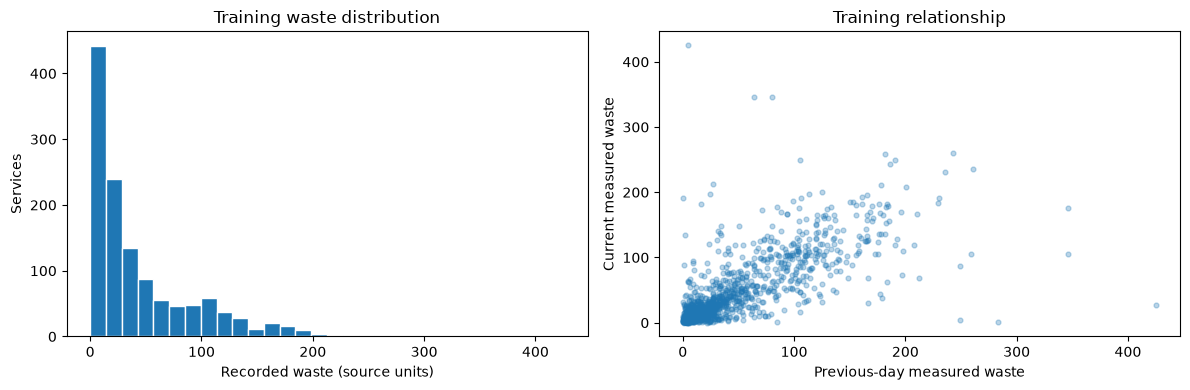

In [5]:
# Inspect TRAINING data only before model selection.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(training[TARGET], bins=30, edgecolor='white')
axes[0].set(xlabel='Recorded waste (source units)', ylabel='Services', title='Training waste distribution')
axes[1].scatter(training['lag_1'], training[TARGET], alpha=0.3, s=12)
axes[1].set(xlabel='Previous-day measured waste', ylabel='Current measured waste', title='Training relationship')
plt.tight_layout()
plt.show()

## 5. Train the ML models — yahin training hoti hai
`X_train` questions/inputs hain; `y_train` actual measured answers hain.
**`model.fit(X_train, y_train)`** model ko relationship sikhata hai.

`candidates()` defines three scikit-learn pipelines: Ridge Regression, Decision Tree
and Random Forest. Har pipeline kitchen encode, numeric inputs scale aur regressor fit karti hai.
`predict()` learned relationship se validation waste estimate karta hai.

In [6]:
X_train = training[FEATURES]
y_train = training[TARGET]
X_validation = validation[FEATURES]
y_validation = validation[TARGET]

models = candidates()
validation_results = {}
for name, model in models.items():
    model.fit(X_train, y_train)  # ACTUAL ML TRAINING
    validation_prediction = np.maximum(0, model.predict(X_validation))
    validation_results[name] = scores(y_validation, validation_prediction)
    print(f'Trained {name}: validation MAE = {validation_results[name]["MAE"]:.3f}')

Trained Ridge Regression: validation MAE = 12.650
Trained Decision Tree: validation MAE = 15.461


Trained Random Forest: validation MAE = 13.141


## 6. Compare ML with simple baselines, then freeze selection
Baselines: previous-day value, recent seven-observation average, historical kitchen average.
Lowest **validation MAE** wins. Baseline win kare toh honestly report karo;
sirf ML use karne ke liye weaker candidate select mat karo. R² classification accuracy nahi hai.

In [7]:
for name, feature in BASELINES.items():
    validation_results[name] = scores(y_validation, validation[feature])
comparison = pd.DataFrame(validation_results).T.sort_values('MAE')
display(comparison)
best_ml_name = min(models, key=lambda name: validation_results[name]['MAE'])
selected_name = min(validation_results, key=lambda name: validation_results[name]['MAE'])
print('Best ML candidate by validation MAE:', best_ml_name)
print('Selected overall method:', selected_name)

,MAE,RMSE,R2
Recent 7 observations mean,12.581987,20.430261,0.775225
Ridge Regression,12.650014,20.060314,0.783292
Random Forest,13.140739,20.746290,0.768218
Historical mean,14.774358,22.833510,0.719234
Previous day,15.458573,25.789162,0.641842
Decision Tree,15.460808,24.522564,0.676159


Best ML candidate by validation MAE: Ridge Regression
Selected overall method: Recent 7 observations mean


## 7. Refit the selected method and evaluate the final holdout
Ab choice frozen hai. Selected ML ho toh train + validation par refit hoti hai.
Selected baseline ko `.fit()` ki zaroorat nahi hoti.

**Rolling next-day evaluation:** test period mein earlier days ke measured actuals later predictions
ke history inputs ban sakte hain. Ye poore future period ka ek saath multi-day forecast nahi hai.

In [8]:
fit_rows = pd.concat([training, validation_all], ignore_index=True)
test = test_all[test_all.kitchen.isin(fit_rows.kitchen.unique())].copy()
final_model = None
if selected_name in models:
    final_model = clone(models[selected_name])
    final_model.fit(fit_rows[FEATURES], fit_rows[TARGET])

payload = {
    'model': final_model, 'selected_name': selected_name, 'features': FEATURES,
    'unit': UNIT, 'known_kitchens': sorted(fit_rows.kitchen.unique().tolist()),
    'training_last_date': str(fit_rows.date.max().date()),
    'evaluation_protocol': 'rolling next-day, previous calendar-day measurement required',
}
test_prediction = predict_selected(payload, test[FEATURES])
test_results = {name: scores(test[TARGET], test[feature]) for name, feature in BASELINES.items()}
test_results[selected_name] = scores(test[TARGET], test_prediction)
print('Scored final test records:', len(test))
print('Excluded unseen-kitchen test records:', len(test_all) - len(test))
display(pd.DataFrame(test_results).T)
baseline_mae = test_results['Previous day']['MAE']
improvement = 100 * (1 - test_results[selected_name]['MAE'] / baseline_mae)
print(f'MAE improvement over previous-day baseline: {improvement:.1f}%')

Scored final test records: 669
Excluded unseen-kitchen test records: 31


,MAE,RMSE,R2
Previous day,13.273244,21.431382,0.649389
Recent 7 observations mean,10.987892,17.603632,0.763447
Historical mean,15.564342,22.589765,0.610464


MAE improvement over previous-day baseline: 17.2%


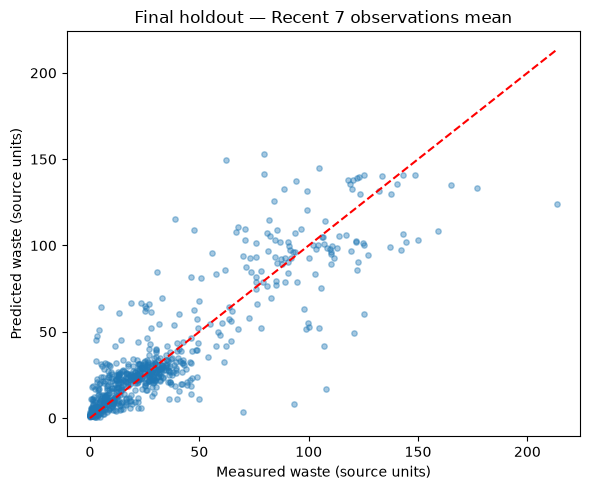

,kitchen,rows,MAE
4,Cyprus / Artisan Burger Bar,1,66.228571
20,kavala / Paraliakon,2,33.042857
15,Santander / Restaurante Machichaco,26,28.796703
19,Tenerife / Tiagaiga,50,23.299429
7,Cyprus / Hilton Cyprus,15,20.787619
3,Copenhagen / Steelhouse,2,19.592857
16,Tenerife / El Tope,52,19.583242
17,Tenerife / Marte,50,18.679429
12,Portugal / Tivoli Oriente,48,10.480655
6,Cyprus / CU Ledras,44,9.514935


In [9]:
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(test[TARGET], test_prediction, alpha=0.4, s=15)
limit = max(test[TARGET].max(), test_prediction.max())
ax.plot([0, limit], [0, limit], 'r--')
ax.set(xlabel='Measured waste (source units)', ylabel='Predicted waste (source units)',
       title=f'Final holdout — {selected_name}')
plt.tight_layout()
plt.show()

per_kitchen = pd.DataFrame([
    {'kitchen': kitchen, 'rows': len(group),
     'MAE': float(np.mean(np.abs(group[TARGET] - group.predicted)))}
    for kitchen, group in test.assign(predicted=test_prediction).groupby('kitchen')
])
display(per_kitchen.sort_values('MAE', ascending=False))

## 8. Save your notebook-trained artifacts
Notebook ke outputs alag names se save honge. Existing app aur CLI model overwrite nahi honge.
Scores/versions save hote hain; model pickle sirf apne trusted local artifacts se load karo.

In [10]:
output = ROOT / 'model'
output.mkdir(exist_ok=True)
metrics = {
    'source': 'https://zenodo.org/records/3355300',
    'source_sha256': hashlib.sha256(RAW_PATH.read_bytes()).hexdigest(),
    'unit': UNIT, 'selected_name': selected_name,
    'validation_results': validation_results, 'test_results': test_results,
    'test_rows': len(test), 'fit_last_date': payload['training_last_date'],
    'test_first_date': str(test.date.min().date()), 'test_last_date': str(test.date.max().date()),
    'protocol': payload['evaluation_protocol'],
    'versions': {'python': platform.python_version(), 'pandas': pd.__version__,
                 'numpy': np.__version__, 'scikit_learn': sklearn.__version__},
}
payload['metrics'] = metrics
with (output / 'real_notebook_model.pkl').open('wb') as f:
    pickle.dump(payload, f)
(output / 'real_notebook_metrics.json').write_text(json.dumps(metrics, indent=2, allow_nan=False) + '\n')
print('Saved:', output / 'real_notebook_model.pkl')

Saved: /Users/namitachhabra/Documents/zerowaste/model/real_notebook_model.pkl


## 9. Predict one historical next day with your saved method
Ye historical example hai. Aaj ki prediction ke liye updated prior-day measured history chahiye.
Forecast helper current/future actuals ignore karta hai aur unseen kitchen / stale history reject karta hai.

In [11]:
with (ROOT / 'model/real_notebook_model.pkl').open('rb') as f:
    saved = pickle.load(f)
display(forecast(saved, clean, 'Copenhagen / Axel', '2018-11-22'))

{'kitchen': 'Copenhagen / Axel',
 'forecast_date': '2018-11-22',
 'predicted_waste': 29.371,
 'unit': 'source weight units (exact CSV unit unconfirmed)',
 'selected_model': 'Recent 7 observations mean',
 'history_last_date': '2018-11-21',
 'notice': 'Historical-data prototype; no kg, financial-loss or preparation claim until unit confirmation.'}

## Interpretation for your report / viva
- Models real measured records par train hue, synthetic labels par nahi.
- Selection validation MAE se hui; final test se candidate choose nahi hua.
- Baseline selected ho toh usse trained ML regressor mat bolo. ML models compare karna valid experiment hai.
- Results covered kitchens ki 2018 services ke liye hain; unseen kitchens aur current Indian operations par reliability establish nahi hui.
- Overall R² kitchen differences se influence ho sakta hai; per-kitchen errors bhi dekho.
- Exact exported weight unit unresolved hai. Financial loss/preparation advice abhi justified nahi hai.
- Test results dekhkar repeated tuning karogi toh final test independent nahi rahega; fresh holdout chahiye hoga.